# Pre-entrega 6: Orquestador Multi-Agente — demo del flujo de delegación

Este notebook importa el código del repo (`state.py`, `agents/`, `graph.py`) y muestra cómo el **Supervisor** delega en el **Investigador** (Vector DB de la PE4) y en el **Analista** (cálculo), valida con su rúbrica y cierra con la **Síntesis**.

Requiere un `.env` con `GOOGLE_API_KEY` (y opcionalmente `PINECONE_API_KEY`), ver `.env.example`.

## 1. Setup

In [1]:
import logging, warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
logging.basicConfig(level=logging.WARNING)

import config
from knowledge_base import obtener_base

print("Modelo:", config.GEMINI_MODEL)
print("Límites: MAX_PASOS =", config.MAX_PASOS, "| MAX_VISITAS_POR_AGENTE =", config.MAX_VISITAS_POR_AGENTE)
print("Modo de búsqueda del Investigador:", obtener_base().modo)

Modelo: gemini-flash-lite-latest
Límites: MAX_PASOS = 6 | MAX_VISITAS_POR_AGENTE = 2


Modo de búsqueda del Investigador: híbrido (BM25 + Pinecone)


## 2. El grafo

`START → supervisor → {investigador | analista | sintesis}`; los especialistas siempre vuelven al supervisor.

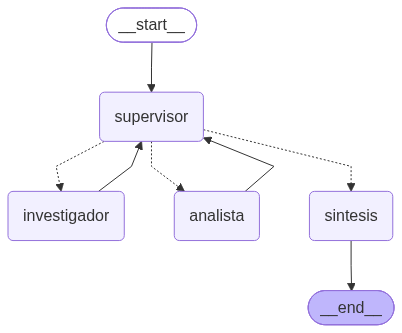

In [2]:
from IPython.display import Image, display
from graph import app

display(Image(app.get_graph().draw_mermaid_png()))

## 3. Herramientas acotadas de cada especialista

El Investigador solo puede **buscar**; el Analista solo puede **calcular**.

In [3]:
from agents.research_agent import HERRAMIENTAS as H_INV, buscar_documentacion_fastapi
from agents.analyst_agent import HERRAMIENTAS as H_ANA, calculadora

print("Investigador:", [t.name for t in H_INV])
print("Analista:    ", [t.name for t in H_ANA])
print()
print(buscar_documentacion_fastapi.invoke({"consulta": "workers gunicorn núcleos memoria"})[:700], "...")
print()
print(calculadora.invoke({"expresion": "(2 * 8) + 1"}))
print(calculadora.invoke({"expresion": "__import__('os').system('dir')"}))  # bloqueado

Investigador: ['buscar_documentacion_fastapi']
Analista:     ['calculadora', 'resumen_estadistico']



[despliegue_en_produccion.pdf, p. 1]
1. Servidores ASGI y workers
Una aplicación FastAPI es una aplicación ASGI: no se ejecuta sola, necesita un servidor ASGI
como Uvicorn, Hypercorn o Granian. En producción se usa el comando `fastapi run main.py`, que
inicia Uvicorn sin recarga automática y escuchando en 0.0.0.0 puerto 8000, o bien `uvicorn
main:app --host 0.0.0.0 --port 80` directamente.
Un único proceso de Python ejecuta el código en un solo núcleo de CPU. Para aprovechar varios
núcleos se levantan varios procesos worker. Uvicorn lo permite con la opción `--workers 4`
(también disponible en `fastapi run --workers 4`). Cada worker es un proceso independiente con
su propia memoria: si la ap ...

(2 * 8) + 1 = 17
Error al calcular '__import__('os').system('dir')': elemento no permitido: Call(func=Attribute(value=Call(func=Name(id='__import__', ct


## 4. Consulta que requiere los DOS dominios

Se transmite el grafo con `stream_mode="updates"` para ver cada delegación: la decisión y la rúbrica del Supervisor, la instrucción que recibe cada especialista, las herramientas que usó y su aporte.

In [4]:
from main import PREGUNTA_DEMO, ejecutar

estado = ejecutar(PREGUNTA_DEMO)

❓ Voy a desplegar mi API de FastAPI en un servidor de 8 núcleos con Gunicorn y workers de Uvicorn. La app carga un modelo de machine learning de 1 GB en memoria. Según la documentación, ¿cuántos workers conviene levantar para empezar y cuánta memoria consumirían en total? Si el servidor tiene 16 GB de RAM, ¿alcanza? Si no alcanza, ¿cuál es la cantidad máxima de workers que entra dejando 2 GB libres para el sistema?



🧭 SUPERVISOR
   rúbrica: datos_con_fuente=✘ calculos_verificados=✘ consistencia=✘ responde_pregunta=✘
   decisión: -> investigador  (No hay contribuciones previas. Se necesita primero la información oficial de la documentación sobre la cantidad recomendada de workers para 8 núcleos.)
   instrucción: Busca en la documentación de FastAPI la recomendación oficial sobre cuántos workers de Uvicorn/Gunicorn conviene levantar para empezar (la fórmula basada en el número de núcleos de CPU, que en este caso son 8 núcleos). Cita la fuente de la documentación.



🔎 INVESTIGADOR
   herramientas usadas: buscar_documentacion_fastapi
   aporte: - Como regla práctica, la documentación sugiere empezar con la fórmula `(2 x cantidad de núcleos) + 1` workers y ajustar con pruebas de carga, ya que el número ideal depende de cuánto tiempo pasa la aplicación esperando E/S [despliegue_en_produccion.pdf, p. 1].
           - Fuente: `despliegue_en_produccion.pdf`, p. 1.



🧭 SUPERVISOR
   rúbrica: datos_con_fuente=✔ calculos_verificados=✘ consistencia=✘ responde_pregunta=✘
   decisión: -> analista  (El investigador ya obtuvo la formula y los datos de la documentacion con su fuente. Ahora falta que el analista realice los calculos exactos de workers recomendados, memoria total, verificacion de si alcanza la RAM y calculo del maximo de workers segun la restriccion de memoria.)
   instrucción: Con los datos obtenidos por el investigador de 8 nucleos de CPU, la formula de (2 x nucleos) + 1 workers, un modelo de 1 GB por worker, 16 GB de RAM total del servidor y 2 GB libres obligatorios para el sistema, calcula: 1) cuantos workers conviene levantar para empezar y cuanta memoria total consumirIan; 2) si alcanza la memoria de 16 GB para esa cantidad inicial; 3) cual es la cantidad maxima de workers que entra dejando 2 GB libres para el sistema.



🧮 ANALISTA
   herramientas usadas: calculadora, calculadora, calculadora
   aporte: 1) Workers iniciales y memoria consumida:
           - Cantidad de workers = (2 * 8) + 1 = 17 workers
           - Memoria total inicial = 17 * 1 GB = 17 GB
           
           2) Verificación de memoria disponible:
           - Memoria máxima para workers (dejando 2 GB libres) = 16 GB - 2 GB = 14 GB
           - Comparación con memoria requerida = 17 GB > 14 GB (por lo tanto, **la memoria de 16 GB no alcanza** para los 17 workers iniciales).
           
           3) Cantidad máxima de workers que entran:
           - Máximo de workers = floor((16 - 2) / 1) = 14 workers
           
           Conclusión: Con 16 GB de RAM y 2 GB reservados para el sistema, no es posible iniciar con los 17 workers recomendados (se excederían por 3 GB). La cantidad máxima que se puede levantar son 14 workers.



🧭 SUPERVISOR
   rúbrica: datos_con_fuente=✔ calculos_verificados=✔ consistencia=✔ responde_pregunta=✔
   decisión: -> FINISH  (Todos los datos de la documentación fueron obtenidos con fuente, los cálculos del analista son correctos y consistentes con los datos, y se responden todas las partes de la pregunta del usuario.)
   cierre: rúbrica de validación aprobada



📝 SINTESIS

RESPUESTA FINAL
Según la documentación, para empezar conviene calcular la cantidad de workers con la fórmula `(2 x cantidad de núcleos) + 1` [despliegue_en_produccion.pdf, p. 1]. 

A continuación se detallan los cálculos clave:

1. **Workers iniciales y memoria consumida:**
   - Cantidad de workers = $(2 \times 8) + 1 = 17$ workers.
   - Memoria total inicial = $17 \times 1\text{ GB} = 17\text{ GB}$.

2. **Verificación con 16 GB de RAM:**
   - Memoria máxima permitida (dejando 2 GB libres) = $16\text{ GB} - 2\text{ GB} = 14\text{ GB}$.
   - Comparación: $17\text{ GB} > 14\text{ GB}$. Por lo tanto, **la memoria no alcanza** para los 17 workers iniciales.

3. **Cantidad máxima de workers:**
   - Máximo de workers = $\text{floor}((16 - 2) / 1) = 14$ workers.

**Conclusión:** No alcanza con 16 GB de RAM para el despliegue sugerido. La cantidad máxima de workers que se puede levantar dejando 2 GB libres para el sistema es de 14.


🗺️  Recorrido: supervisor -> investigador -> sup

### Estado compartido: quién aportó qué

In [5]:
for c in estado["contribuciones"]:
    print(f"paso {c['paso']} | {c['agente']:<12} | herramientas={c['herramientas']}")
    print(f"   instrucción: {c['instruccion'][:160]}")
print()
for d in estado["decisiones"]:
    print(f"supervisor (paso {d['paso']}) -> {d['next']:<12} rúbrica={d['rubrica']}")

paso 1 | investigador | herramientas=['buscar_documentacion_fastapi']
   instrucción: Busca en la documentación de FastAPI la recomendación oficial sobre cuántos workers de Uvicorn/Gunicorn conviene levantar para empezar (la fórmula basada en el 
paso 2 | analista     | herramientas=['calculadora', 'calculadora', 'calculadora']
   instrucción: Con los datos obtenidos por el investigador de 8 nucleos de CPU, la formula de (2 x nucleos) + 1 workers, un modelo de 1 GB por worker, 16 GB de RAM total del s

supervisor (paso 0) -> investigador rúbrica={'datos_con_fuente': False, 'calculos_verificados': False, 'consistencia': False, 'responde_pregunta': False}
supervisor (paso 1) -> analista     rúbrica={'datos_con_fuente': True, 'calculos_verificados': False, 'consistencia': False, 'responde_pregunta': False}
supervisor (paso 2) -> FINISH       rúbrica={'datos_con_fuente': True, 'calculos_verificados': True, 'consistencia': True, 'responde_pregunta': True}


## 5. Ruteo dinámico: una pregunta que NO necesita al Analista

El Supervisor no sigue un guion fijo: si la pregunta no requiere cálculos, cierra sin pasar por el Analista.

In [6]:
estado2 = ejecutar("¿Qué código de estado HTTP devuelve FastAPI cuando falla la validación de un parámetro?")

❓ ¿Qué código de estado HTTP devuelve FastAPI cuando falla la validación de un parámetro?



🧭 SUPERVISOR
   rúbrica: datos_con_fuente=✘ calculos_verificados=✔ consistencia=✘ responde_pregunta=✘
   decisión: -> investigador  (No hay contribuciones previas. Necesitamos que el investigador busque el código de estado HTTP para la falla de validación en la documentación.)
   instrucción: Busca en la documentación técnica de FastAPI qué código de estado HTTP devuelve cuando falla la validación de un parámetro, asegurándote de incluir la fuente exacta.



🔎 INVESTIGADOR
   herramientas usadas: buscar_documentacion_fastapi
   aporte: * Cuando falla la validación de un parámetro, FastAPI responde automáticamente con el código de estado HTTP **422 Unprocessable Entity** [parametros_de_ruta_y_query.md, p. 1].
           * El cuerpo de la respuesta es un objeto JSON que incluye la clave `detail` con el detalle de los errores de validación [parametros_de_ruta_y_query.md, p. 1].



🧭 SUPERVISOR
   rúbrica: datos_con_fuente=✔ calculos_verificados=✔ consistencia=✔ responde_pregunta=✔
   decisión: -> FINISH  (El investigador aportó el código de estado HTTP exacto (422) con su respectiva fuente y la pregunta no requiere cálculos.)
   cierre: rúbrica de validación aprobada



📝 SINTESIS

RESPUESTA FINAL
Cuando falla la validación de un parámetro, FastAPI responde automáticamente con el código de estado HTTP **422 Unprocessable Entity** [parametros_de_ruta_y_query.md, p. 1]. 

Además, el cuerpo de la respuesta consiste en un objeto JSON que contiene la clave `detail`, la cual incluye el detalle específico de los errores de validación [parametros_de_ruta_y_query.md, p. 1].


🗺️  Recorrido: supervisor -> investigador -> supervisor -> sintesis
   Delegaciones: 1 | Motivo de cierre: rúbrica de validación aprobada


## 6. Guardas anti "Supervisor Infinito"

Simulamos un supervisor defectuoso que pide refinar al Investigador **para siempre** (con dobles de prueba, sin gastar llamadas al LLM). La guarda en código corta el ciclo al agotar `MAX_VISITAS_POR_AGENTE`.

In [7]:
from langchain_core.messages import AIMessage
from agents.supervisor import DecisionSupervisor, RubricaValidacion
from graph import construir_grafo
from state import estado_inicial

class AgenteFalso:
    def invoke(self, entrada):
        return {"messages": [AIMessage(content="dato incompleto, sin fuente")]}

class LLMFalso:
    def invoke(self, prompt):
        return AIMessage(content="(síntesis)")

siempre_refinar = lambda mensajes: DecisionSupervisor(
    rubrica=RubricaValidacion(datos_con_fuente=False, calculos_verificados=False,
                              consistencia=False, responde_pregunta=False),
    next="investigador", instruccion="Refiná: citá la fuente", razon="falta la fuente")

app_defectuosa = construir_grafo(investigador=AgenteFalso(), analista=AgenteFalso(),
                                 decisor=siempre_refinar, llm_sintesis=LLMFalso())
final = app_defectuosa.invoke(estado_inicial("pregunta cualquiera"))
for d in final["decisiones"]:
    print(f"paso {d['paso']}: -> {d['next']}  ({d['razon']})")
print("\nMotivo de cierre:", final["motivo_cierre"])

paso 0: -> investigador  (falta la fuente)
paso 1: -> investigador  (falta la fuente)
paso 2: -> FINISH  (falta la fuente -> forzado: 'investigador' ya agotó sus 2 intentos (refinamientos))

Motivo de cierre: 'investigador' ya agotó sus 2 intentos (refinamientos)
